## Sequential Algorithm for Open-Pit Mine Scheduling Problem

### Installing packages

In [1]:
!pip install -q pandas==3.0.2 numpy==2.4.4 mip==2.0.0 highspy==1.15.1 highsbox==1.15.1 gurobipy==13.0.1 matplotlib==3.10.8 plotly==6.6.0

### Importing packages

In [2]:
import time, pandas as pd, gurobipy as gp, plotly.express as px, matplotlib.pyplot as plt, numpy as np
from mip import *

### Loading block model file

In [3]:
# Load block model 
cols = ["id", "x", "y", "z", "dest", "phase", "AuRec", "AuFA", "tons", "co3", "orgc", "sulf",
        "Mcost", "Pcost", "Tcost", "Tvalue", "Bvalue", "rc_Stockpile", "rc_RockChar" ]

# Read the block model (space-separated format)
blocks = pd.read_csv("w23.blocks", sep=r"\s+", header=None, names=cols, engine="python")

blocks["blockvalue"] = blocks["Bvalue"]

# Determine destination 
blocks["destination"] = blocks["dest"]

# Add a column to store the extraction period (initially empty)
blocks["period"] = pd.NA

print(f"Loaded {len(blocks):,} blocks")

Loaded 74,260 blocks


### Loading block precedences file

In [4]:
# Load precedence relations (Precedence file format: block_id  n_prec  prec1  prec2  ... )
precedence = {}
with open("w23.prec") as f:
    for line in f:
        parts = line.strip().split()
        block_id = int(parts[0])
        n_prec = int(parts[1])
        precedence[block_id] = [int(parts[k]) for k in range(2, 2+n_prec)]

print(f"Loaded {sum(len(precs) for precs in precedence.values()):,} precedences")

Loaded 764,786 precedences


### Sequential Algorithm for Open-Pit Mine Scheduling

In [5]:
# Parameters 
max_period = 12       # Maximum number of scheduling periods
MC = 68_000_000        # Mine capacity (tons) C0
PC_sulf = 3_610_000        # Processing capacity (tons) C1
PC_ox = 1_000_000       # Processing capacity (tons) C2
alpha = 0.10           # Discount rate for Net Present Value (NPV)

# Sequential Optimization 
code_start = time.time()
period_profit = []   # Store discounted values per period
extracted = set()    # Keep track of already extracted blocks

# Build a model using Gurobi Solver, if available, or use open-source CBC solver (MIP Package Default)
try:
    Model(sense=MAXIMIZE, solver_name="GRB").clear()
    solver_name = "GRB"
except Exception:
    try:
        Model(sense=MAXIMIZE, solver_name="HIGHS").clear()   # HiGHS when no Gurobi license is active
        solver_name = "HIGHS"
    except Exception:
        solver_name = "CBC"
print(f"Using {solver_name} solver")
print("Starting optimization")

# Loop over scheduling periods
for t in range(max_period):

    # Available blocks = those not extracted yet
    B = list(blocks.index[~blocks["id"].isin(extracted)])
    if not B:
        break  # Stop if no available blocks remain

    # Extract data for available blocks
    ids = blocks.loc[B, "id"].tolist()
    d = blocks.loc[B, "destination"].tolist()
    v = blocks.loc[B, "blockvalue"].tolist()
    w = blocks.loc[B, "tons"].tolist()

    model = Model(sense=MAXIMIZE, solver_name=solver_name)
    model.max_seconds = 600  # 10 minutes

    # Decision variables: x[b] = 1 if block b is extracted in this period
    x = [model.add_var(var_type=BINARY) for _ in B]

    # Objective: maximize undiscounted profit in this period
    model.objective = xsum(x[b] * v[b] for b in range(len(B)))

    # Precedence constraints: a block can only be extracted if its predecessors are extracted
    id_to_var = {ids[b]: b for b in range(len(B))}
    for bid in ids:
        if bid in precedence:
            for prec in precedence[bid]:
                if prec in extracted:
                    continue  # Already extracted in earlier period
                elif prec in id_to_var:
                    model += x[id_to_var[bid]] <= x[id_to_var[prec]]
                else:
                    # Predecessor not extracted yet → force this block = 0
                    model += x[id_to_var[bid]] == 0

    # Capacity constraint 
    model += xsum(w[b] * x[b] for b in range(len(B))) <= MC
    model += xsum(w[b] * x[b] for b in range(len(B)) if d[b] == 1) <= PC_sulf
    model += xsum(w[b] * x[b] for b in range(len(B)) if d[b] == 2) <= PC_ox

    # Solve optimization 
    opt_start = time.time()
    model.optimize()
    opt_time = time.time() - opt_start

    # Check solution status
    if model.status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE) and model.objective_value > 0:
        undiscounted_value = model.objective_value
        discounted_value = undiscounted_value / ((1 + alpha) ** t)
        period_profit.append(discounted_value)

        # Update extracted blocks
        files_start = time.time()
        selected = []
        for b, var in enumerate(x):
            if var.x > 0.5:  # If block is selected
                bid = ids[b]
                extracted.add(bid)
                blocks.loc[blocks["id"] == bid, "period"] = t
                selected.append(bid)
        files_time = time.time() - files_start

        # Print summary for this period
        print(f"Period: {t} | "
              f"Undiscounted: {undiscounted_value:,.0f} | " f"Discounted: {discounted_value:,.0f} | " f"Blocks: {len(selected)} | "
              f"Opt Time (min): {opt_time/60:.2f} | " f"Files Time (min): {files_time/60:.2f}")
    else:
        break

    # Clear model (free memory before next period)
    model.clear()

# Final Results 
npv = sum(period_profit)  # Net Present Value
print(f"\nNPV: {npv:,.0f}")
print(f"Total blocks extracted: {len(extracted)}")
print(f"Code Time: {(time.time()-code_start)/60:.2f} minutes")

# Save solution 
blocks.to_csv("w23_solution.csv", index=False)

Using GRB solver
Starting optimization
Period: 0 | Undiscounted: 146,540,271 | Discounted: 146,540,271 | Blocks: 7599 | Opt Time (min): 0.85 | Files Time (min): 0.05
Period: 1 | Undiscounted: 67,178,958 | Discounted: 61,071,780 | Blocks: 2778 | Opt Time (min): 4.87 | Files Time (min): 0.02
Period: 2 | Undiscounted: 56,015,384 | Discounted: 46,293,706 | Blocks: 8189 | Opt Time (min): 7.29 | Files Time (min): 0.07
Period: 3 | Undiscounted: 49,474,721 | Discounted: 37,171,090 | Blocks: 4330 | Opt Time (min): 3.26 | Files Time (min): 0.03
Period: 4 | Undiscounted: 37,118,009 | Discounted: 25,352,100 | Blocks: 5399 | Opt Time (min): 5.25 | Files Time (min): 0.04
Period: 5 | Undiscounted: 50,465,360 | Discounted: 31,335,018 | Blocks: 4373 | Opt Time (min): 0.43 | Files Time (min): 0.04
Period: 6 | Undiscounted: 35,042,118 | Discounted: 19,780,362 | Blocks: 2551 | Opt Time (min): 0.31 | Files Time (min): 0.02
Period: 7 | Undiscounted: 28,144,584 | Discounted: 14,442,622 | Blocks: 3130 | Opt T

### Mine Scheduling 3D Plot

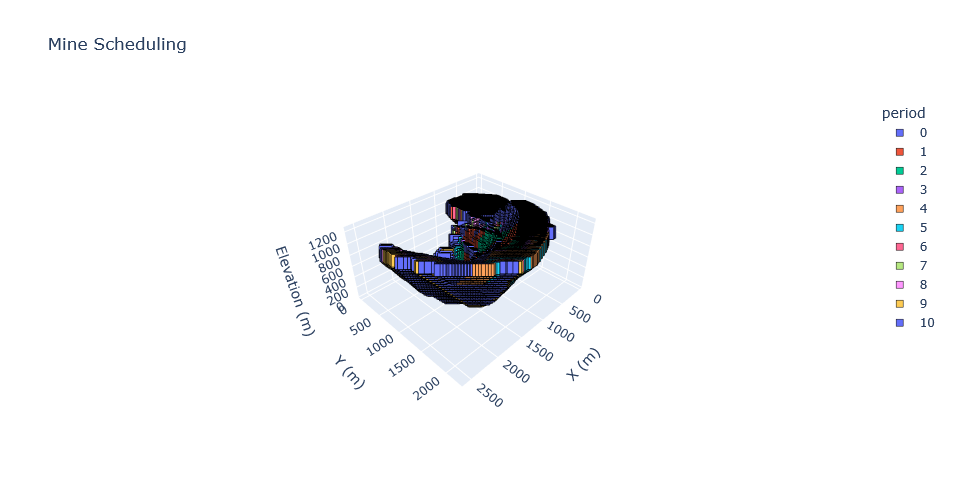

In [6]:
# Block dimensions
dx, dy, dz = 25, 25, 20

# Filter extracted blocks and prepare data
d = blocks.loc[blocks.period.notna()].copy()
d["period"] = d["period"].astype(int)
d[["x","y","z"]] *= [dx, dy, dz]
d["period"] -= d["period"].min()
d["period"] = d["period"].astype(str)

# Axis scaling for correct proportions
r = d[["x","y","z"]].max() - d[["x","y","z"]].min()
s = r.max()

# 3D categorical scatter with Plotly default colors
fig = px.scatter_3d(d, x="x", y="y", z="z", color="period", color_discrete_sequence=px.colors.qualitative.Plotly,
    category_orders={"period": sorted(d["period"], key=int)}, labels={"color": "Periods"}, 
    title="Mine Scheduling", width=900, height=500).update_traces(marker=dict(symbol="square", size=7, 
    line=dict(width=0.5, color="black"))).update_layout(scene=dict(xaxis_title="X (m)", yaxis_title="Y (m)", 
    zaxis_title="Elevation (m)", aspectmode="manual", aspectratio=dict(x=r.x/s, y=r.y/s, z=r.z/s)))
fig.show()

In [7]:
# Salve 3D Plot 
fig.write_html("w23_plot.html", full_html=True, include_plotlyjs="cdn",
    config={"responsive": True}, default_width="100vw", default_height="100vh")

### Capacity & Grade Chart

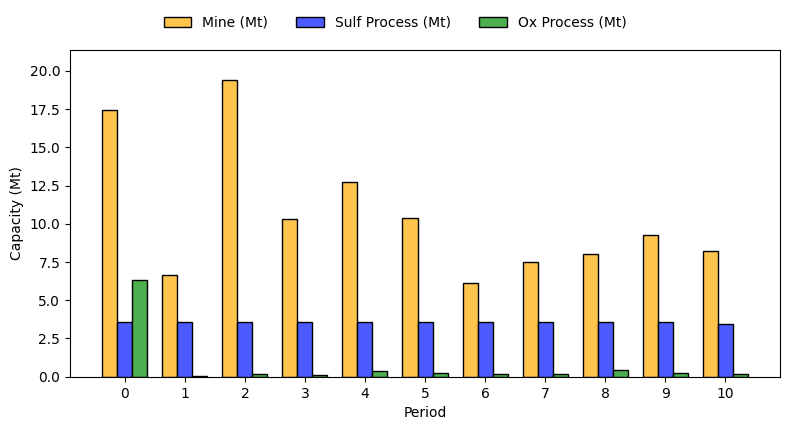

In [8]:
# Consider only extracted blocks
df = blocks.dropna(subset=["period"]).copy()
# Processed material only
df["w_sulf"] = df["tons"] * (df["destination"] == 1)   # sulfide mill tonnage
df["w_ox"]   = df["tons"] * ((df["destination"] == 2) | (df["destination"] == 3))  # oxide tonnage
# Aggregate by period
summary = (df.groupby("period", as_index=False).agg(ton_mine=("tons", "sum"), ton_sulf=("w_sulf", "sum"), ton_ox=("w_ox", "sum")))
# Plot
x = np.arange(len(summary))
w = 0.25
fig, ax1 = plt.subplots(figsize=(8, 4))
# Bars: Mine vs Sulf vs Oxide (Mt)
ax1.bar(x - w, summary["ton_mine"] / 1e6, w, label="Mine (Mt)", color="#FFC44D", edgecolor="black")
ax1.bar(x,     summary["ton_sulf"] / 1e6, w, label="Sulf Process (Mt)", color="#4C5BFF", edgecolor="black")
ax1.bar(x + w, summary["ton_ox"]   / 1e6, w, label="Ox Process (Mt)", color="#4CAF50", edgecolor="black")
ax1.set_xlabel("Period")
ax1.set_ylabel("Capacity (Mt)")
ax1.set_xticks(x)
ax1.set_xticklabels(summary["period"].astype(int))
# Y-axis from zero to slightly above max
ax1.set_ylim(0, 1.1 * max(summary["ton_mine"].max(), summary["ton_sulf"].max(), summary["ton_ox"].max()) / 1e6)
# Visual hierarchy
ax1.patch.set_visible(False)
# Legend
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)
plt.tight_layout()
plt.show()

In [9]:
# Salve plot
fig.savefig("w23_results.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()